In [1]:
import sys
sys.path.append("..")

from src.dataset import ForestDataset, preprocess

val_amazon = ForestDataset("amazon", "Validation")
x, y = val_amazon[0]
print(len(val_amazon), x.shape, y.shape)

100 torch.Size([4, 512, 512]) torch.Size([1, 512, 512])


In [2]:
import time
import torch
import segmentation_models_pytorch as smp
from torch.utils.data import DataLoader, ConcatDataset

from src.dataset import ForestDataset, BASES

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",   # pretrained; smp adapts the first conv to 4 bands
    in_channels=4,                # R, G, B, NIR
    classes=1,                    # one logit per pixel (forest vs not)
)

x = torch.randn(2, 4, 256, 256)
print(model(x).shape)             # expect [2, 1, 256, 256]
print("params:", sum(p.numel() for p in model.parameters()) / 1e6, "M")

torch.Size([2, 1, 256, 256])
params: 24.439505 M


In [3]:
train_ds = ConcatDataset([ForestDataset(b, "Training", train=True) for b in BASES])
loader = DataLoader(train_ds, batch_size=8, shuffle=True, num_workers=2)

dice = smp.losses.DiceLoss(mode="binary")
bce = torch.nn.BCEWithLogitsLoss()
opt = torch.optim.AdamW(model.parameters(), lr=1e-3)

model.train()
x, y = next(iter(loader))
for i in range(3):
    t = time.time()
    opt.zero_grad()
    out = model(x)
    loss = bce(out, y) + dice(out, y)
    loss.backward()
    opt.step()
    print(f"step {i}: loss={loss.item():.3f}, {time.time() - t:.1f}s")

print("steps per epoch:", len(loader))

step 0: loss=1.477, 2.9s
step 1: loss=1.190, 2.6s
step 2: loss=1.062, 2.6s
steps per epoch: 123


In [4]:
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm

val_loaders = {b: DataLoader(ForestDataset(b, "Validation"), batch_size=4) for b in BASES}

@torch.no_grad()
def evaluate(model, loader):
    """IoU and F1 for the forest class over a whole loader."""
    model.eval()
    tp = fp = fn = 0.0
    for x, y in loader:
        pred = (torch.sigmoid(model(x)) > 0.5).float()
        tp += (pred * y).sum().item()
        fp += (pred * (1 - y)).sum().item()
        fn += ((1 - pred) * y).sum().item()
    iou = tp / (tp + fp + fn + 1e-9)
    f1 = 2 * tp / (2 * tp + fp + fn + 1e-9)
    return iou, f1

In [5]:
EPOCHS = 20          # test run first; raise to ~20 once it works

# fresh model, since the timing cell already updated the old one
model = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet", in_channels=4, classes=1)
opt = torch.optim.AdamW(model.parameters(), lr=3e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
dice = smp.losses.DiceLoss(mode="binary")
bce = torch.nn.BCEWithLogitsLoss()

Path("../models").mkdir(exist_ok=True)
best = 0.0

for epoch in range(EPOCHS):
    model.train()
    total = 0.0
    for x, y in tqdm(loader, desc=f"epoch {epoch + 1}/{EPOCHS}"):
        opt.zero_grad()
        out = model(x)
        loss = bce(out, y) + dice(out, y)
        loss.backward()
        opt.step()
        total += loss.item()
    sched.step()

    scores = {b: evaluate(model, l) for b, l in val_loaders.items()}
    mean_iou = float(np.mean([s[0] for s in scores.values()]))
    print(f"epoch {epoch + 1}: train loss {total / len(loader):.3f} | "
          + " | ".join(f"{b}: IoU {s[0]:.3f} F1 {s[1]:.3f}" for b, s in scores.items()))

    if mean_iou > best:
        best = mean_iou
        torch.save(model.state_dict(), "../models/unet_resnet34_best.pt")
        print(f"  saved best model (mean IoU {best:.3f})")

epoch 1/20:   0%|          | 0/123 [00:00<?, ?it/s]

epoch 1: train loss 0.584 | amazon: IoU 0.924 F1 0.961 | atlantic: IoU 0.752 F1 0.859
  saved best model (mean IoU 0.838)


epoch 2/20:   0%|          | 0/123 [00:00<?, ?it/s]

epoch 2: train loss 0.325 | amazon: IoU 0.945 F1 0.972 | atlantic: IoU 0.835 F1 0.910
  saved best model (mean IoU 0.890)


epoch 3/20:   0%|          | 0/123 [00:00<?, ?it/s]

epoch 3: train loss 0.283 | amazon: IoU 0.949 F1 0.974 | atlantic: IoU 0.849 F1 0.918
  saved best model (mean IoU 0.899)


... (30 outputs left out)

epoch 19/20:   0%|          | 0/123 [00:00<?, ?it/s]

epoch 19: train loss 0.148 | amazon: IoU 0.960 F1 0.980 | atlantic: IoU 0.892 F1 0.943
  saved best model (mean IoU 0.926)


epoch 20/20:   0%|          | 0/123 [00:00<?, ?it/s]

epoch 20: train loss 0.146 | amazon: IoU 0.960 F1 0.980 | atlantic: IoU 0.890 F1 0.942


In [6]:
model = smp.Unet(encoder_name="resnet34", encoder_weights=None, in_channels=4, classes=1)
model.load_state_dict(torch.load("../models/unet_resnet34_best.pt"))
model.eval()

test_loaders = {b: DataLoader(ForestDataset(b, "Test"), batch_size=4) for b in BASES}
for b, l in test_loaders.items():
    iou, f1 = evaluate(model, l)
    print(f"{b}: test IoU {iou:.3f}  F1 {f1:.3f}")

amazon: test IoU 0.958  F1 0.978
atlantic: test IoU 0.882  F1 0.938


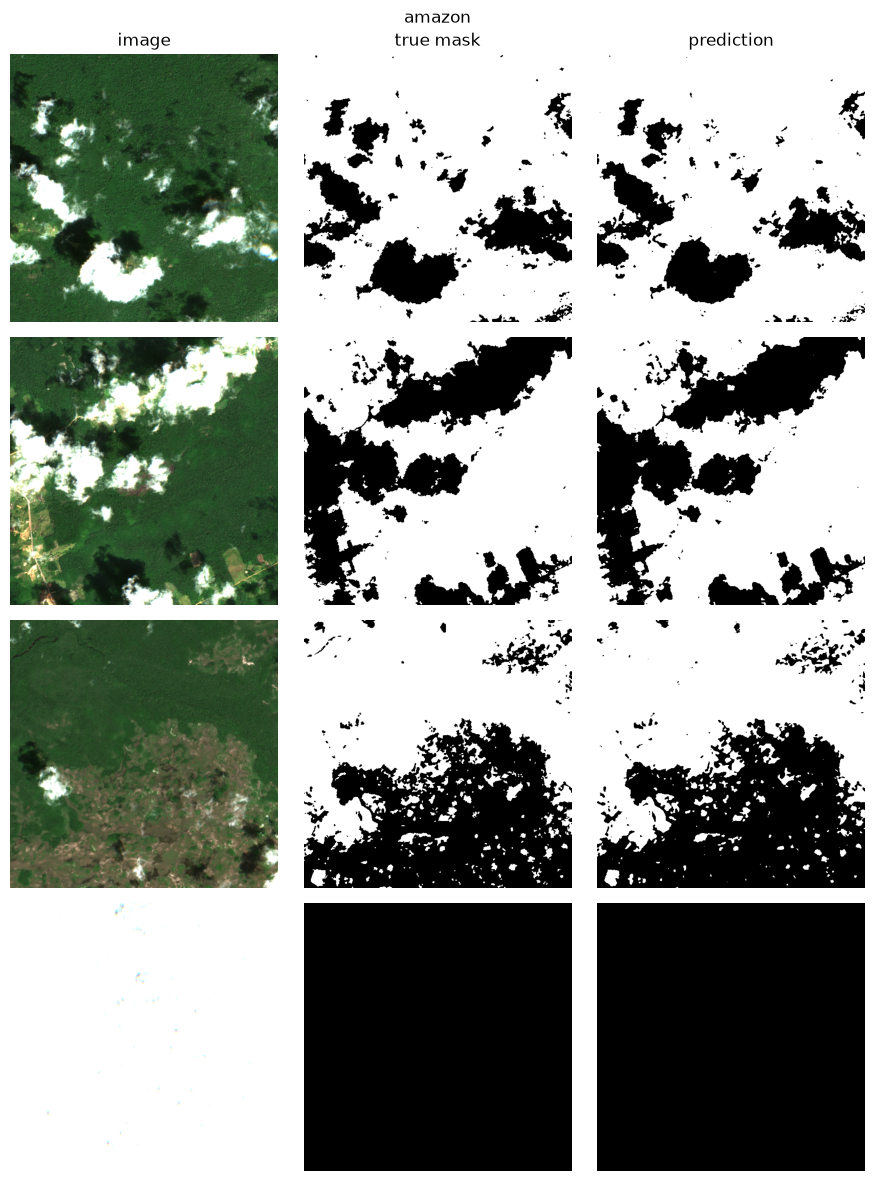

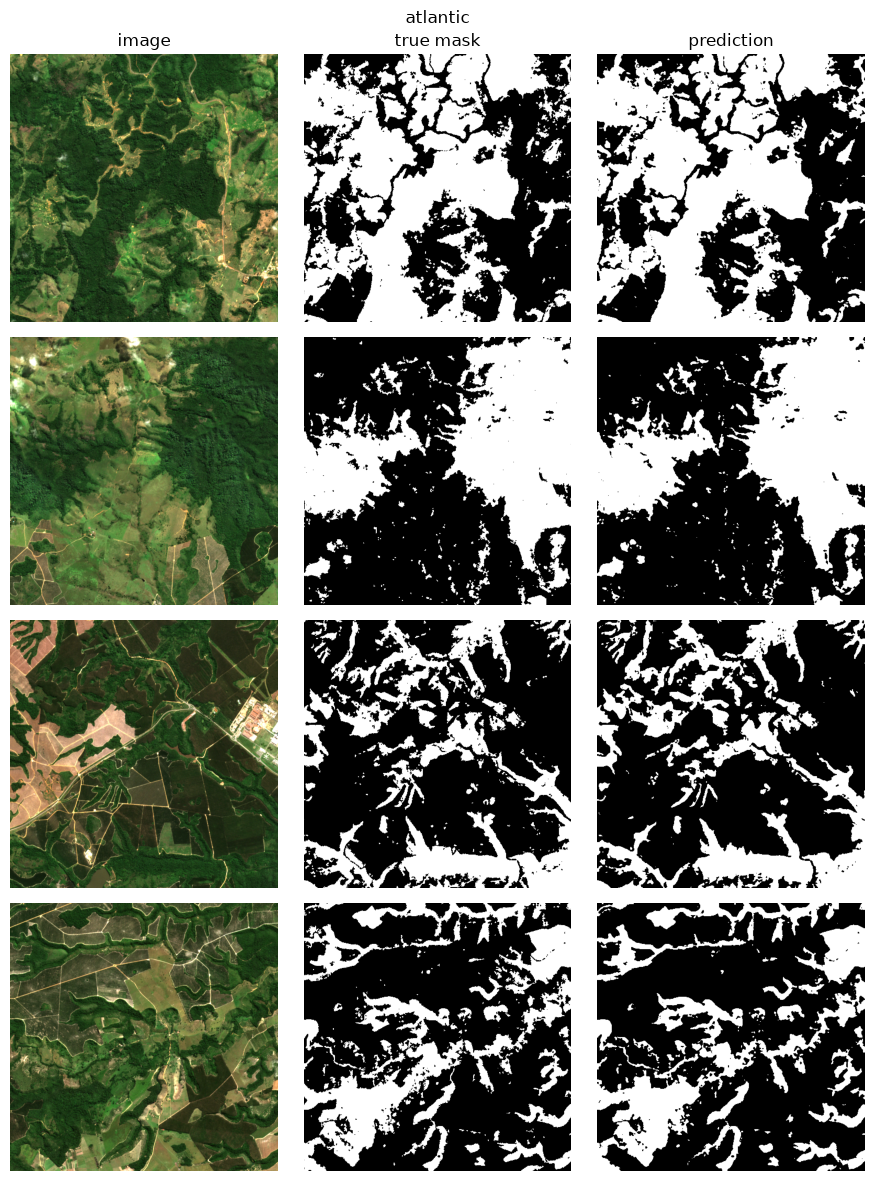

In [7]:
import matplotlib.pyplot as plt
from src.dataset import MEAN, STD

def show(biome, n=4):
    ds = ForestDataset(biome, "Test")
    fig, ax = plt.subplots(n, 3, figsize=(9, 3 * n))
    for i in range(n):
        x, y = ds[i]
        with torch.no_grad():
            pred = (torch.sigmoid(model(x[None])) > 0.5)[0, 0].numpy()
        refl = x.numpy() * STD + MEAN                      # undo normalization for display
        rgb = np.clip(np.transpose(refl[:3], (1, 2, 0)) / 0.15, 0, 1)
        ax[i, 0].imshow(rgb)
        ax[i, 1].imshow(y[0], cmap="gray", vmin=0, vmax=1)
        ax[i, 2].imshow(pred, cmap="gray", vmin=0, vmax=1)
        for a in ax[i]: a.axis("off")
    for a, t in zip(ax[0], ["image", "true mask", "prediction"]): a.set_title(t)
    fig.suptitle(biome)
    plt.tight_layout(); plt.show()

show("amazon")
show("atlantic")